# Solution B: classical string selection + orbital optimisation

**Grader energy: −108.949402 Ha** at 300 strings per spin. This is our submission.

1. Start from the Hartree–Fock string in the natural orbitals of our DMRG reference (`results/dmrg_rdm1.npy`).
2. Grow the string set with candidates ranked by their second-order energy gain, then prune back to 300 in gradual
   steps.
3. Rotate the orbitals with CASSCF for the fixed strings and re-select strings in the new basis. Repeat until a cycle
   gains less than 0.01 mHa.


In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt

from eval.score import score_result
from n2sqd.result import Result

# run from the repository root: the Hamiltonian cache and reference energies use paths relative to it
if Path.cwd().name == "notebooks":
    os.chdir("..")


def show_score(path):
    s = score_result(Result.load(path))
    print(f"grader energy         {s.energy:.6f} Ha")
    print(f"strings per spin      {s.dims[0]} / {s.dims[1]}")
    print(f"claim check passes    {s.matches}")
    print(f"official grader code  {s.grader_energy} Ha (agrees: {s.grader_agrees})")
    print(f"gap to exact          {s.gap_to_reference_mha:+.1f} mHa ({s.reference_label})")
    print(f"vs CCSD               {-s.below_ccsd_mha:+.1f} mHa")
    return s


def chain_energies(files):
    """Energy after the start of each run and after every completed cycle, from the logged metrics."""
    labels, energies = [], []
    for file in files:
        metrics = json.loads(Path(file).read_text())
        run = Path(file).stem
        for event in metrics["events"]:
            phase = event["phase"]
            if phase in ("refine-0", "sqd-0") or phase.startswith("cycle-"):
                labels.append(f"{run} start" if phase in ("refine-0", "sqd-0") else f"{run} cycle {phase[6:]}")
                energies.append(event["energy"])
    return labels, energies


def plot_chain(labels, energies, title):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(range(len(energies)), energies, marker="o")
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("energy / Ha")
    ax.ticklabel_format(axis="y", useOffset=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


## Score the committed result

The same validation and energy code as the official grader, run offline (under 2 minutes).

In [2]:
score = show_score("results/best/track-b/result.npz")

Recomputing the energy of best_subspace (up to two minutes)...


grader energy         -108.949402 Ha
strings per spin      300 / 300
claim check passes    True
official grader code  -108.949402 Ha (agrees: True)
gap to exact          +32.6 mHa (DMRG extrapolated (estimate))
vs CCSD               -39.9 mHa


## How the run converged

Energy after the grow–prune start and after each orbital-optimisation cycle of the main run (`chain`) and the polish (`polish`).

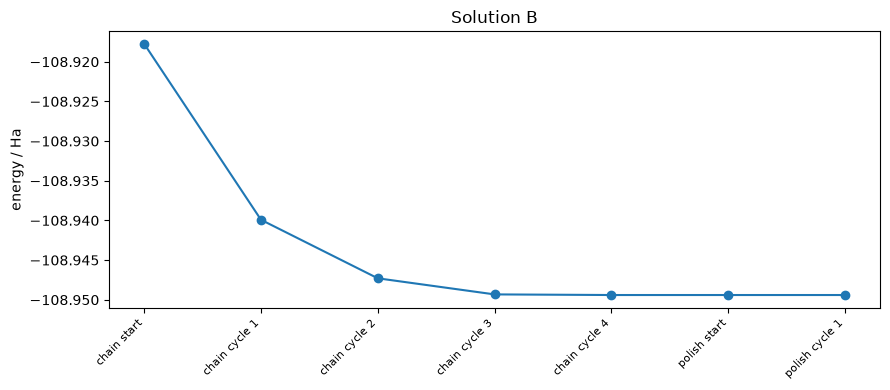

In [3]:
labels, energies = chain_energies([
    "results/best/track-b/runs/chain.json",
    "results/best/track-b/runs/polish.json",
])
plot_chain(labels, energies, "Solution B")

## Reproduce from scratch

About 6.5 h on a 12-core machine, then a 15-minute polish. Set `RUN_FULL = True` to run it.

In [4]:
RUN_FULL = False

CHAIN = [
    "-m n2sqd.trackb --out output/solution-b/chain --start hf --orbitals dmrg-no --select-cutoff 5e-4 --ci-cutoff 5e-4 --max-new 700 --refine-iterations 6 --prune-steps 4 --oo-cycles 6 --oo-macro 80 --reselect-iterations 2",
    "-m n2sqd.trackb --out output/solution-b/polish --start file:output/solution-b/chain/result.npz --orbitals file:output/solution-b/chain/orbitals.npy --refine-iterations 0 --oo-cycles 6 --oo-macro 80 --reselect-iterations 2 --max-new 700 --prune-steps 4 --select-cutoff 5e-4 --ci-cutoff 5e-4 --cycle-tol 1e-5",
]

if RUN_FULL:
    for args in CHAIN:
        subprocess.run([sys.executable, *args.split()], check=True)
    show_score("output/solution-b/polish/result.npz")
else:
    print("RUN_FULL is False. The chain:")
    print("\n".join("python " + args for args in CHAIN))

RUN_FULL is False. The chain:
python -m n2sqd.trackb --out output/solution-b/chain --start hf --orbitals dmrg-no --select-cutoff 5e-4 --ci-cutoff 5e-4 --max-new 700 --refine-iterations 6 --prune-steps 4 --oo-cycles 6 --oo-macro 80 --reselect-iterations 2
python -m n2sqd.trackb --out output/solution-b/polish --start file:output/solution-b/chain/result.npz --orbitals file:output/solution-b/chain/orbitals.npy --refine-iterations 0 --oo-cycles 6 --oo-macro 80 --reselect-iterations 2 --max-new 700 --prune-steps 4 --select-cutoff 5e-4 --ci-cutoff 5e-4 --cycle-tol 1e-5
